# County migration patterns and characteristic profiles

In this section, clustering methods are used to perform two independent analyses of the same counties:
1. Migration-rate clustering to describe different movement patterns
2. County-characteristic clustering to discover county profiles, from which a comparsion of migration outcomes can be made 

Figures, numeric sample CSVs, assignments and a measured results JSON are exported directly to `website/` by the cells below.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/us_migration').is_dir())
sys.path.insert(0, str(ROOT/'src'))
from us_migration.unsupervised import (
    FEATURES, LABELS, MIGRATION, COLORS, STANDARDIZED_FEATURES, STANDARDIZED_MIGRATION, prepare_cross_section,
    configure_plots, save_figure, sample_image, write_json, provenance)
configure_plots()
YEAR, SEED = 2023, 42
INPUT = ROOT/'data/processed/analysis_county_year.parquet'
panel = pd.read_parquet(INPUT)
counties, characteristics, migration = prepare_cross_section(panel, YEAR)
# This is an exploratory fit to all eligible 2023 counties, not a held-out prediction test.
# Source imputation is inherited unchanged; scalers below fit only this cross-section.
X = StandardScaler().fit_transform(characteristics)
M = StandardScaler().fit_transform(migration)
OUT = ROOT/'website/assets/phase2'
DOWNLOAD = ROOT/'website/data/phase2'
OUT.mkdir(parents=True, exist_ok=True)
DOWNLOAD.mkdir(parents=True, exist_ok=True)
print(f'{YEAR}: {len(counties):,} counties; {int(counties.socioeconomic_imputed.sum())} with imputed predictors; '
      f'{int(counties.net_rate_iqr_flag.sum())} migration outlier flags retained.')
assert not counties.county_fips.duplicated().any()
assert X.shape == (len(counties), 13)
assert np.allclose(X.mean(axis=0), 0, atol=1e-10)
from us_migration.outcomes import OUTCOME_DEFINITIONS, RATE_FIELDS, COUNT_FIELDS
from IPython.display import HTML

2023: 3,050 counties; 6 with imputed predictors; 133 migration outlier flags retained.


## Overview

Clustering groups observations using similarity without a supplied class label. This section performs different clustering methods and compares their results.

Partitional k-means assigns each observation to one of k centroids and minimizes within-cluster squared Euclidean distances. It favors compact groups and is sensitive to feature scaling, initialization and outliers.

Agglomerative hierarchical clustering starts with individual counties and repeatedly merges groups by average linkage, giving a dendrogram rather than a single partition. When merging groups by average linkage, the algorithm computes the mean of all pairwise distances between members of two groups, then proceeds to merge the two groups with the smallest mean of pairwise distances. The distance measure used here is the cosine distance, which is **1 − cosine similarity** on the same standardized input. Cosine emphasizes direction relative to the mean profile and discounts vector magnitude. Standardization can create negative coordinates and cosine distances up to 2. Zero-length vectors have undefined cosine distance, so the code rejects them explicitly.

The following two images use illustrative toy data, not measured county findings.
References: [k-means and hierarchical clustering](https://scikit-learn.org/stable/modules/clustering.html),
[silhouette analysis](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html).

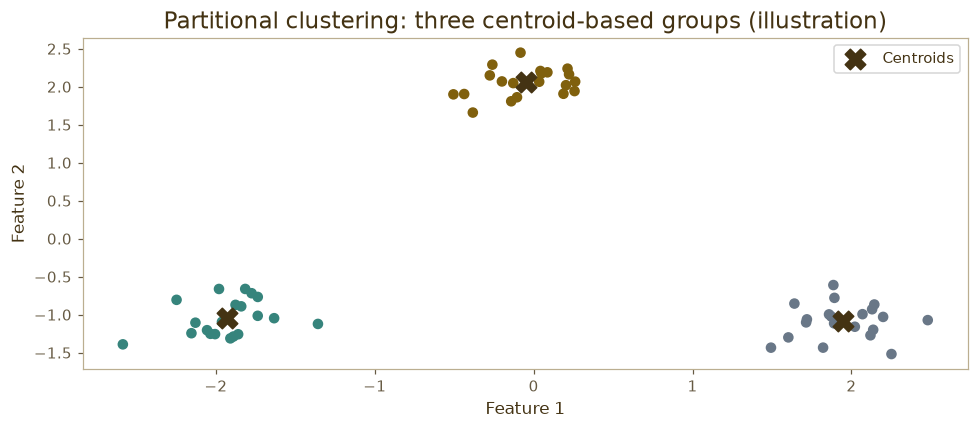

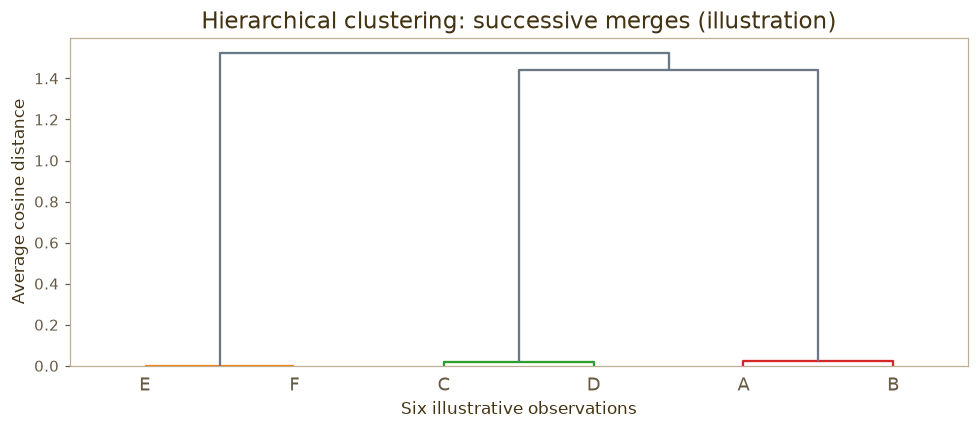

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA

rng = np.random.default_rng(SEED)
toy = np.vstack([rng.normal(c, .30, (20, 2)) for c in [(-2, -1), (0, 2), (2, -1)]])
with threadpool_limits(limits=1):
    toy_fit = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit(toy)
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(*toy.T, c=[COLORS[i] for i in toy_fit.labels_], s=35)
ax.scatter(*toy_fit.cluster_centers_.T, marker='X', s=180, c='#443313', label='Centroids')
ax.set(title='Partitional clustering: three centroid-based groups (illustration)', xlabel='Feature 1', ylabel='Feature 2')
ax.legend(); save_figure(fig, OUT, 'clustering-overview-partitional.png')
fig, ax = plt.subplots(figsize=(9, 4))
toy_z = StandardScaler().fit_transform(toy[[0, 1, 20, 21, 40, 41]])
dendrogram(linkage(toy_z, method='average', metric='cosine'), ax=ax,
           labels=['A', 'B', 'C', 'D', 'E', 'F'], above_threshold_color='#697787')
ax.set(title='Hierarchical clustering: successive merges (illustration)', ylabel='Average cosine distance', xlabel='Six illustrative observations')
save_figure(fig, OUT, 'clustering-overview-hierarchy.png')

## Data preparation

Use the validated `analysis_county_year.parquet` from notebook 01, restricted to **2023** and
`geography_level == 'county'`. Alaska and Connecticut state substitutes are excluded, not treated as counties.
Each eligible county has equal weight.

The 13 county characteristics cover population size, age, income, housing, poverty, employment, education,
FEMA incidents, precipitation and temperature. Log10 transforms population, income, home value and rent;
log1p transforms nonnegative incident counts. These transformations reduce long right tails without removing counties.
Z-score each transformed column to mean zero and population standard deviation one. Percentages enter once;
their numerator/denominator counts do not enter again. Correlated housing/economic variables can still give that
domain more influence, so the resulting profiles depend on this feature specification.

**Inputs contain only numeric measurements, with no outcome labels.** County IDs/names, year,
imputation flags, existing migration categories and migration outcomes stay outside the characteristic matrix.
Keep row keys separately for interpretation. Existing imputation remains documented; no new missing values
are filled. Ordinary outliers are retained, so inspect small clusters before interpreting them.
Temperature and precipitation are annual conditions, not long-run climate normals; incidents measure FEMA
declarations, not total hazard exposure. Monetary values are not local cost-of-living adjusted.


For the separate migration analysis, use only inflow and outflow per 1,000 ACS residents, standardized
independently. Net rate is their exact difference and is not added as a redundant third input.
Migration-driven groups describe outcomes by construction; they are not evidence that characteristics explain migration.
Standardized values are dimensionless z-scores. After scaling, sample DataFrames, CSVs and published snapshots use unit-free names: `temperature`, `precipitation`, `poverty`, `inflow` and `outflow`. Original-unit source and outcome columns retain their definitions. Z-scoring changes mean and scale; it does not impose a normal distribution.


,log10_population,median_age,log10_income,log10_home_value,log10_rent,poverty_pct,unemployment_pct,vacancy_pct,homeownership_pct,bachelors_plus_pct,log1p_incidents,precipitation_inches,temperature_f
0,4.773,39.2,4.844,5.296,3.079,10.684,2.542,8.928,74.910,28.283,0.693,49.81,66.292
1,5.380,43.7,4.875,5.458,3.083,10.515,3.194,26.359,77.535,32.798,0.000,49.37,69.883
2,4.394,40.7,4.646,5.041,2.809,21.921,5.709,22.406,67.489,11.465,0.693,49.11,66.692
3,4.345,41.3,4.709,5.123,2.904,20.512,9.984,16.711,77.176,11.468,0.000,46.88,64.667
4,4.773,40.9,4.786,5.230,2.871,14.095,5.835,11.358,79.506,15.579,0.000,53.83,63.208


,log10_population,median_age,log10_income,log10_home_value,log10_rent,poverty,unemployment,vacancy,homeownership,bachelors_plus,log1p_incidents,precipitation,temperature
0,0.450,-0.473,0.358,0.143,1.039,-0.613,-0.954,-0.766,0.210,0.420,1.492,0.981,1.155
1,1.421,0.383,0.645,0.894,1.072,-0.642,-0.672,0.996,0.525,0.864,-0.575,0.947,1.586
2,-0.156,-0.188,-1.469,-1.045,-1.192,1.281,0.415,0.597,-0.680,-1.234,1.492,0.928,1.203
3,-0.233,-0.074,-0.886,-0.666,-0.406,1.044,2.263,0.021,0.481,-1.234,-0.575,0.759,0.961
4,0.450,-0.150,-0.178,-0.167,-0.680,-0.038,0.470,-0.520,0.761,-0.829,-0.575,1.285,0.786


,inflow,outflow
0,1.601,1.435
1,0.730,-0.393
2,-1.212,-0.535
3,-0.560,-0.756
4,-0.291,-0.376


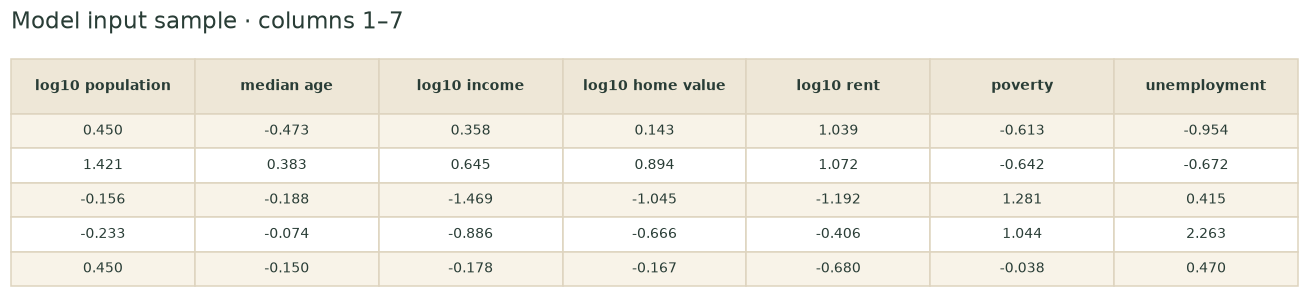

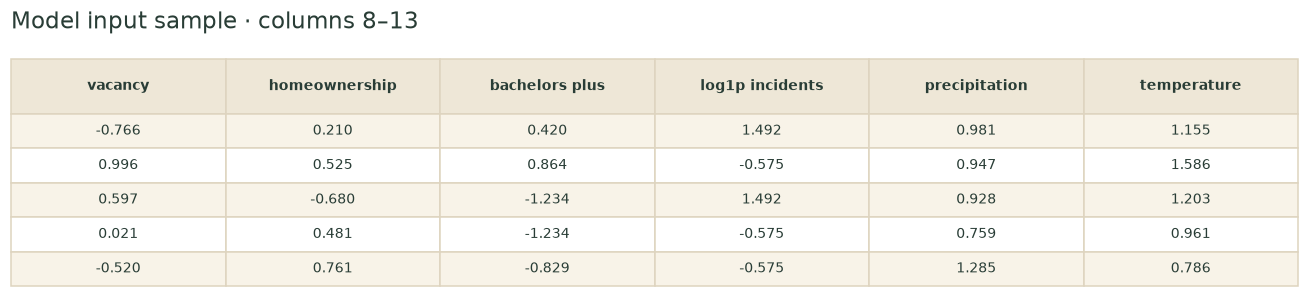

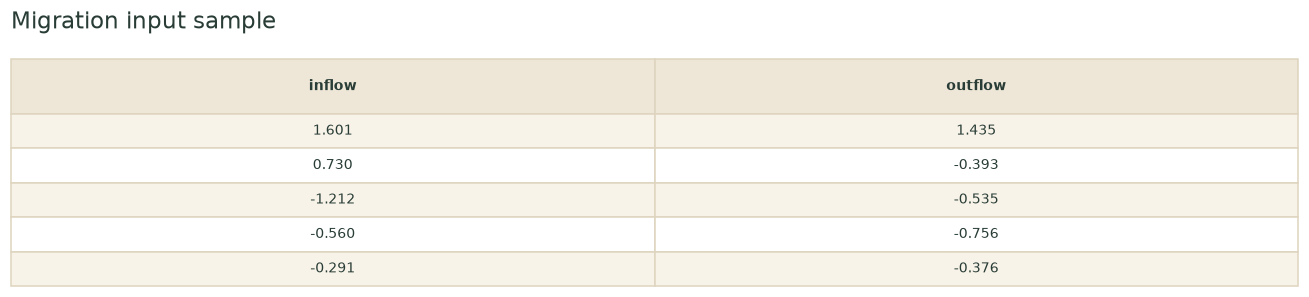

In [3]:
display(characteristics.head().round(3))
display(pd.DataFrame(X, columns=STANDARDIZED_FEATURES).head().round(3))
display(pd.DataFrame(M, columns=STANDARDIZED_MIGRATION).head().round(3))
characteristics.head(20).to_csv(DOWNLOAD/'characteristics-transformed-sample.csv', index=False)
pd.DataFrame(X, columns=STANDARDIZED_FEATURES).head(20).to_csv(DOWNLOAD/'characteristics-standardized-sample.csv', index=False)
pd.DataFrame(M, columns=STANDARDIZED_MIGRATION).head(20).to_csv(DOWNLOAD/'migration-standardized-sample.csv', index=False)
counties[['county_fips', 'county_name', 'year']].head(20).to_csv(DOWNLOAD/'sample-row-keys.csv', index=False)
for start, stop, suffix in [(0, 7, 'a'), (7, 13, 'b')]:
    sample_image(pd.DataFrame(X, columns=STANDARDIZED_FEATURES).iloc[:5, start:stop], OUT,
                 f'clustering-characteristics-sample-{suffix}.png',
                 f'Model input sample · columns {start+1}–{stop}')
sample_image(pd.DataFrame(M, columns=STANDARDIZED_MIGRATION).head(), OUT,
             'clustering-migration-sample.png', 'Migration input sample')

## K-means comparison

Evaluate **k = 2 through 8** for each input view with 20 initializations and seed 42. The silhouette compares within-cluster cohesion with nearest-other-cluster separation and ranges from −1 to 1. Choose the largest mean silhouette within this range (ties favor the smaller k); do not use migration outcome differences to select characteristic clusters.

In [4]:
K_VALUES = list(range(2, 9))
views = {'migration': M, 'characteristics': X}
fits, rows = {}, []
with threadpool_limits(limits=1):
    for view, matrix in views.items():
        for k in K_VALUES:
            model = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(matrix)
            score = silhouette_score(matrix, model.labels_, metric='euclidean')
            sizes = np.bincount(model.labels_)
            fits[view, 'kmeans', k] = model.labels_
            rows.append(dict(view=view, method='kmeans', k=k, silhouette=float(score),
                             min_size=int(sizes.min()), max_size=int(sizes.max()), inertia=float(model.inertia_)))
metrics = pd.DataFrame(rows)
display(metrics.round(4))

,view,method,k,silhouette,min_size,max_size,inertia
0,migration,kmeans,2,0.5383,784,2266,2908.2582
1,migration,kmeans,3,0.4303,349,1382,1941.2135
2,migration,kmeans,4,0.4185,69,1337,1445.1010
3,migration,kmeans,5,0.3958,26,1291,1145.9220
4,migration,kmeans,6,0.3548,25,991,979.6947
5,migration,kmeans,7,0.3547,2,987,851.7619
6,migration,kmeans,8,0.3263,2,818,760.0982
7,characteristics,kmeans,2,0.2220,964,2086,31056.5455
8,characteristics,kmeans,3,0.1788,782,1334,26516.5701
9,characteristics,kmeans,4,0.1538,476,1084,24552.7891


## Hierarchical comparison

Use average linkage and cosine distance on the same rows and standardized columns. Cut each full tree
at k = 2 through 8 and score each partition with cosine silhouette. This makes the proposed tree cut
explicit; a dendrogram has no uniquely correct k. The displayed dendrograms truncate the tree to its last
30 merged nodes for readability. Parentheses indicate the number of underlying counties, not county names.

,view,method,k,silhouette,min_size,max_size,inertia
0,migration,kmeans,2,0.5383,784,2266,2908.2582
1,migration,kmeans,3,0.4303,349,1382,1941.2135
2,migration,kmeans,4,0.4185,69,1337,1445.1010
3,migration,kmeans,5,0.3958,26,1291,1145.9220
4,migration,kmeans,6,0.3548,25,991,979.6947
5,migration,kmeans,7,0.3547,2,987,851.7619
6,migration,kmeans,8,0.3263,2,818,760.0982
7,characteristics,kmeans,2,0.2220,964,2086,31056.5455
8,characteristics,kmeans,3,0.1788,782,1334,26516.5701
9,characteristics,kmeans,4,0.1538,476,1084,24552.7891


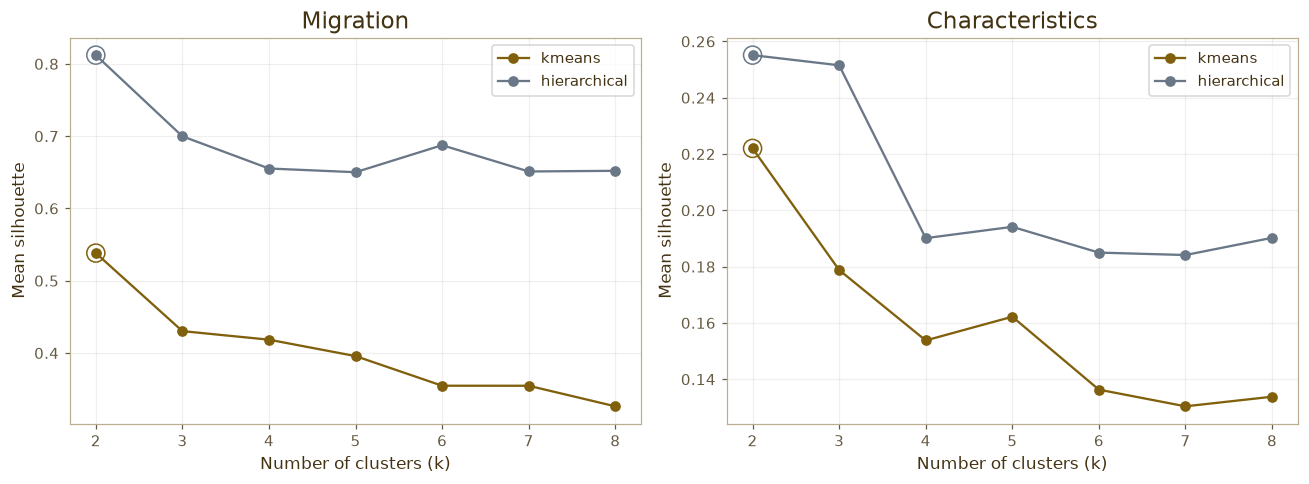

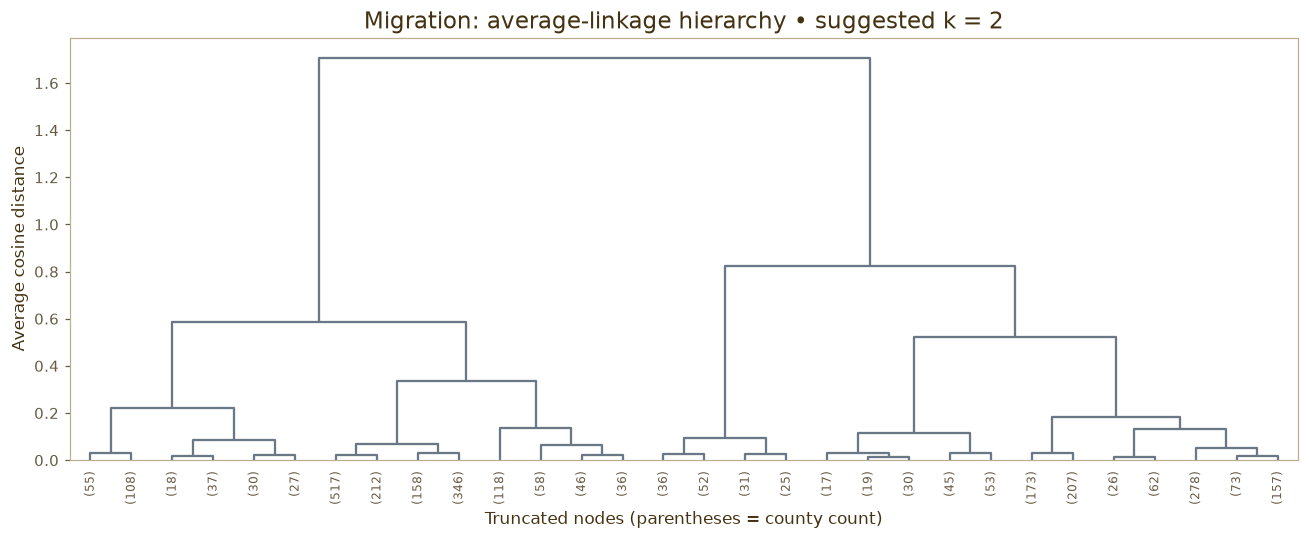

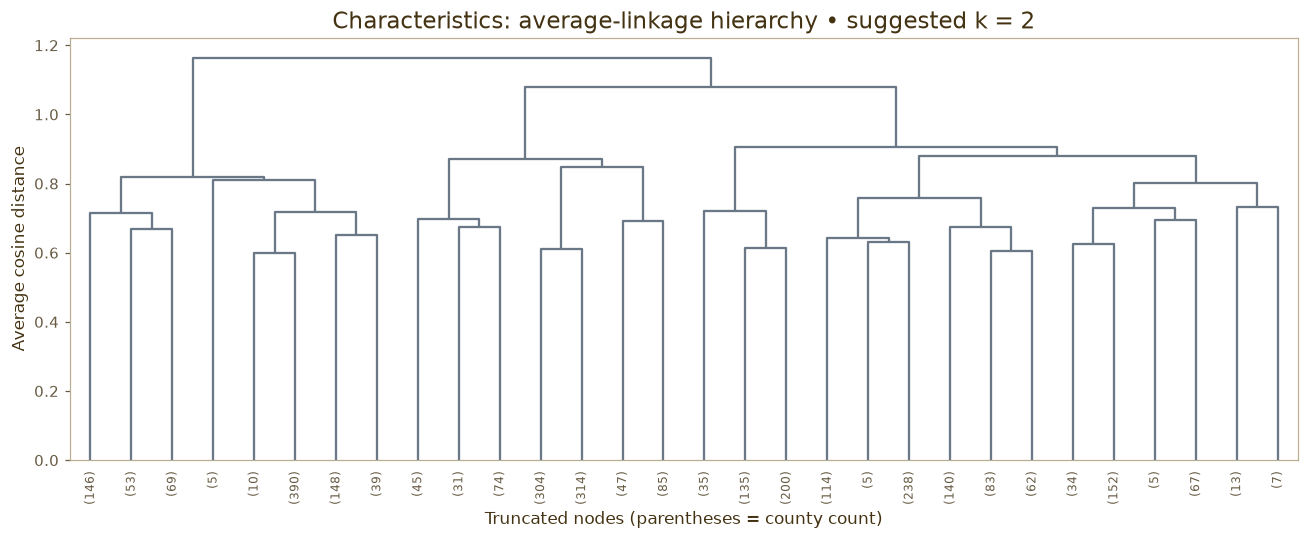

In [5]:
trees = {}
with threadpool_limits(limits=1):
    for view, matrix in views.items():
        assert np.all(np.linalg.norm(matrix, axis=1) > 1e-12), 'Undefined cosine distance for zero vector'
        distance = pdist(matrix, metric='cosine')
        assert np.isfinite(distance).all()
        trees[view] = linkage(distance, method='average')
        for k in K_VALUES:
            labels = cut_tree(trees[view], n_clusters=k).ravel()
            sizes = np.bincount(labels)
            fits[view, 'hierarchical', k] = labels
            rows.append(dict(view=view, method='hierarchical', k=k,
                silhouette=float(silhouette_score(matrix, labels, metric='cosine')),
                min_size=int(sizes.min()), max_size=int(sizes.max()), inertia=None))
metrics = pd.DataFrame(rows)
metrics.to_csv(DOWNLOAD/'clustering-metrics.csv', index=False)
selected = {(view, method): int(group.sort_values(['silhouette', 'k'], ascending=[False, True]).iloc[0].k)
            for (view, method), group in metrics.groupby(['view', 'method'])}
display(metrics.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, view in zip(axes, views):
    for method, color in [('kmeans', COLORS[0]), ('hierarchical', COLORS[1])]:
        data = metrics.loc[(metrics.view == view) & (metrics.method == method)]
        ax.plot(data.k, data.silhouette, 'o-', color=color, label=method)
        best = selected[view, method]
        ax.scatter(best, data.loc[data.k == best, 'silhouette'].iloc[0], s=140, facecolors='none', edgecolors=color)
    ax.set(title=view.title(), xlabel='Number of clusters (k)', ylabel='Mean silhouette', xticks=K_VALUES)
    ax.legend(); ax.grid(alpha=.2)
save_figure(fig, OUT, 'clustering-silhouette.png')
for view in views:
    fig, ax = plt.subplots(figsize=(12, 5))
    dendrogram(trees[view], truncate_mode='lastp', p=30, show_leaf_counts=True,
               leaf_rotation=90, leaf_font_size=8, color_threshold=0, above_threshold_color=COLORS[1], ax=ax)
    ax.set(title=f'{view.title()}: average-linkage hierarchy • suggested k = {selected[view, "hierarchical"]}',
           ylabel='Average cosine distance', xlabel='Truncated nodes (parentheses = county count)')
    save_figure(fig, OUT, f'clustering-{view}-dendrogram.png')

## Results

### County profiles and migration outcomes

Characteristics clustering uses all 13 standardized features; migration clustering uses standardized inflow and outflow rates. The heatmap shows each cluster's mean standardized characteristics; the outcome plots show unweighted county distributions. Overlapping outcome distributions are expected; a difference in group medians does not establish causation or predictive accuracy.

### Characteristics profiles

Rates are IRS individuals per 1,000 ACS residents; Q1 and Q3 bound the middle half of counties.

,Net migration median,Net migration Q1,Net migration Q3,Inflow median,Inflow Q1,Inflow Q3,Outflow median,Outflow Q1,Outflow Q3
cluster,,,,,,,,,
1,2.00,-2.44,8.06,51.31,40.82,64.13,48.05,40.96,57.22
2,1.31,-3.09,6.59,41.97,34.12,50.47,40.88,35.55,46.61


K-means selects **k=2** with Euclidean silhouette **0.222**. Average-linkage hierarchical clustering selects **k=2** with cosine silhouette **0.255**. Each maximizes its own silhouette among k=2–8. The adjusted Rand index is **0.548**, indicating moderate agreement: the methods share some group structure while assigning many county pairs differently. ARI is adjusted for chance, with 0 representing chance-level agreement and 1 identical partitions. This description uses ARI as a continuum; silhouette scores should be compared within each distance metric.

Hierarchy,1,2
K-means,,
1,720,244
2,140,1946


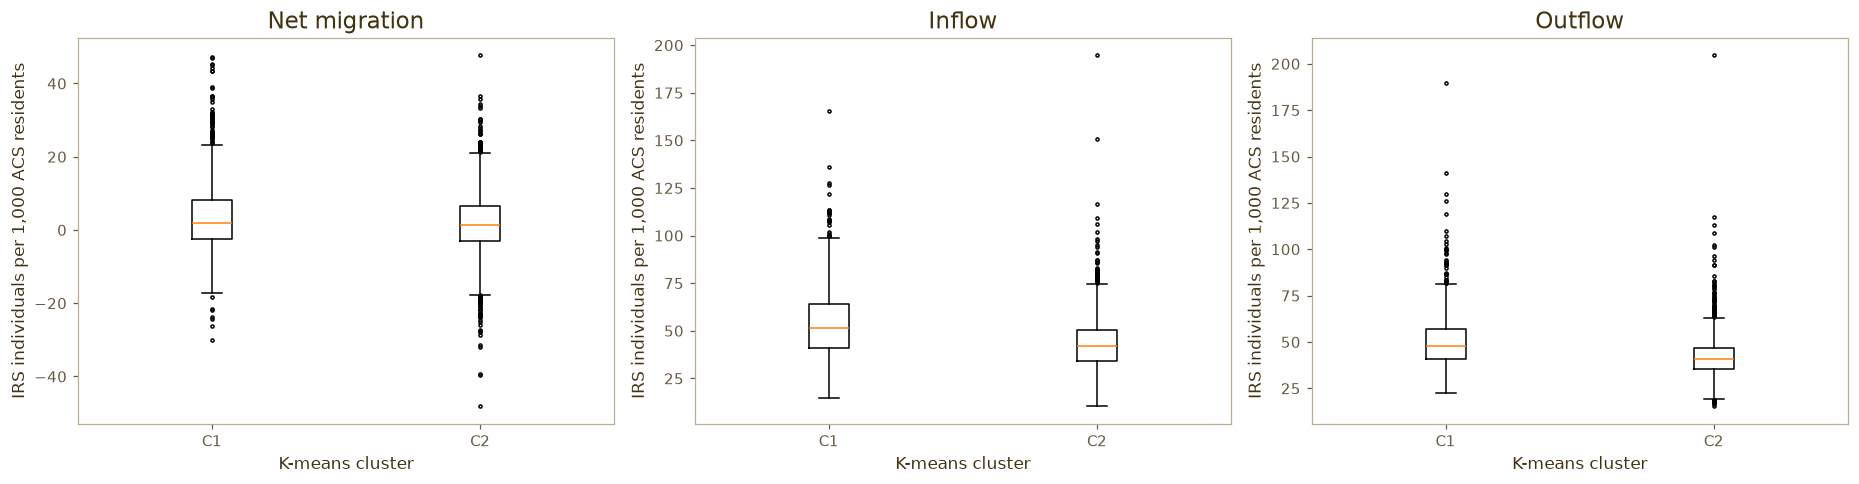

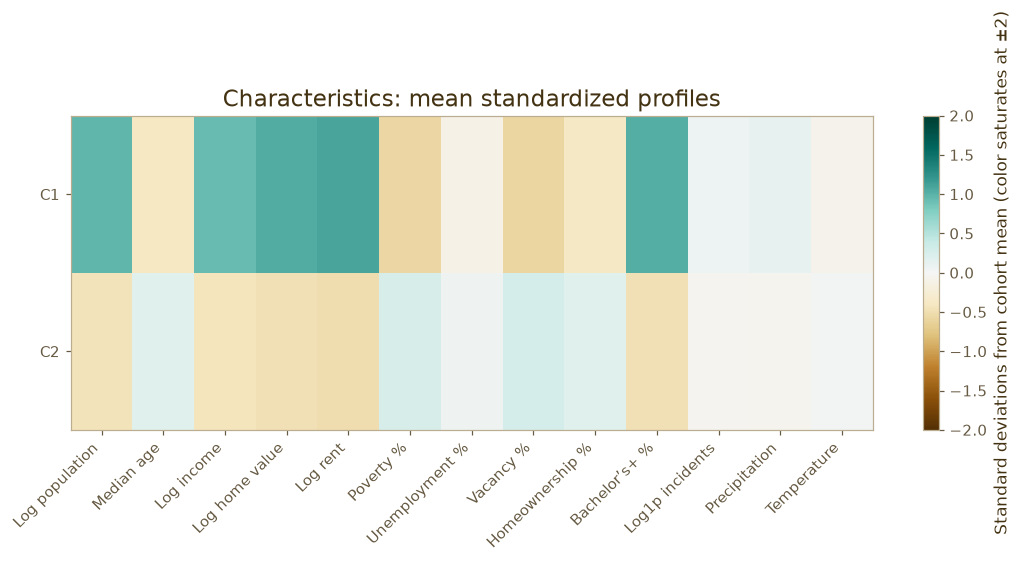

### Migration profiles

Rates are IRS individuals per 1,000 ACS residents; Q1 and Q3 bound the middle half of counties.

,Net migration median,Net migration Q1,Net migration Q3,Inflow median,Inflow Q1,Inflow Q3,Outflow median,Outflow Q1,Outflow Q3
cluster,,,,,,,,,
1,7.81,-0.18,14.50,64.39,57.98,73.74,56.23,52.09,64.17
2,0.62,-3.49,4.49,40.12,33.35,46.54,39.91,34.88,44.14


K-means selects **k=2** with Euclidean silhouette **0.538**. Average-linkage hierarchical clustering selects **k=2** with cosine silhouette **0.812**. Each maximizes its own silhouette among k=2–8. The adjusted Rand index is **0.448**, indicating moderate agreement: the methods share some group structure while assigning many county pairs differently. ARI is adjusted for chance, with 0 representing chance-level agreement and 1 identical partitions. This description uses ARI as a continuum; silhouette scores should be compared within each distance metric.

Hierarchy,1,2
K-means,,
1,784,0
2,500,1766


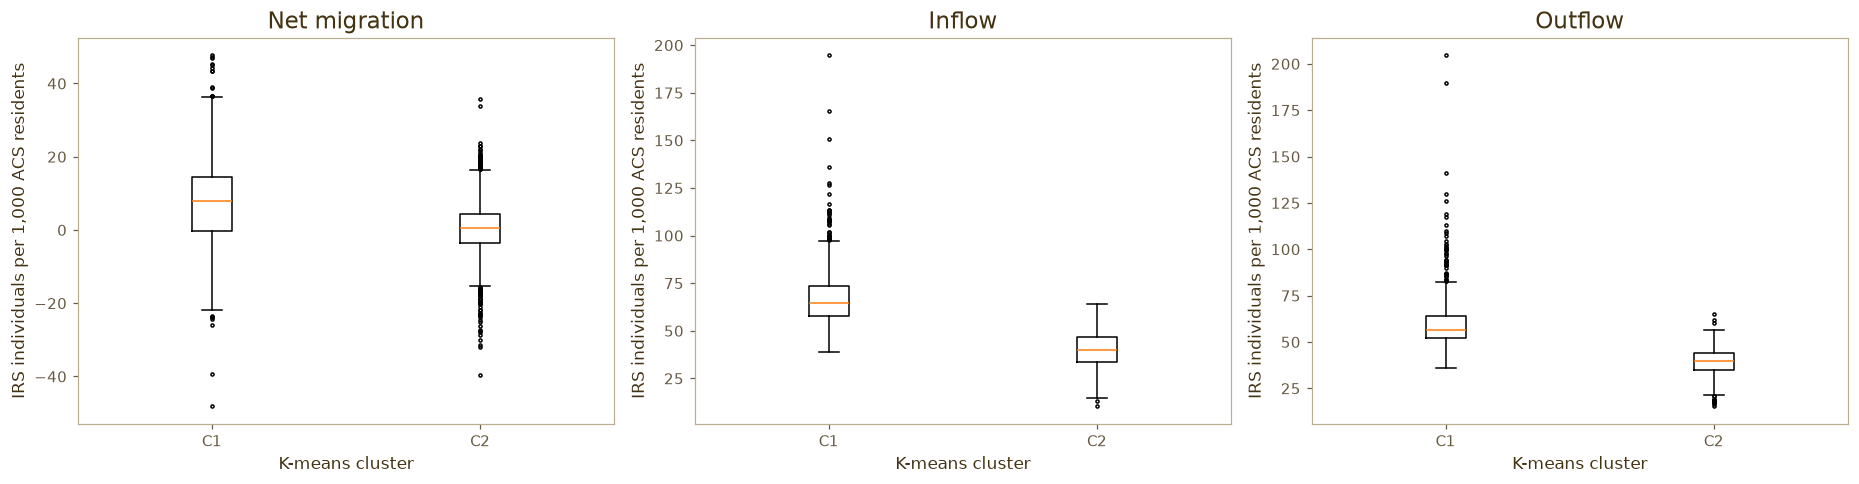

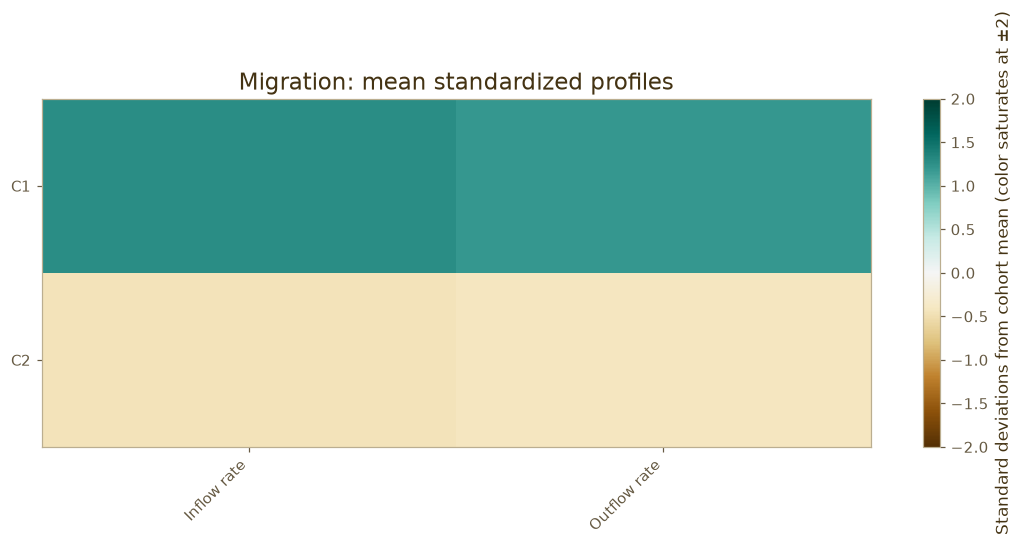

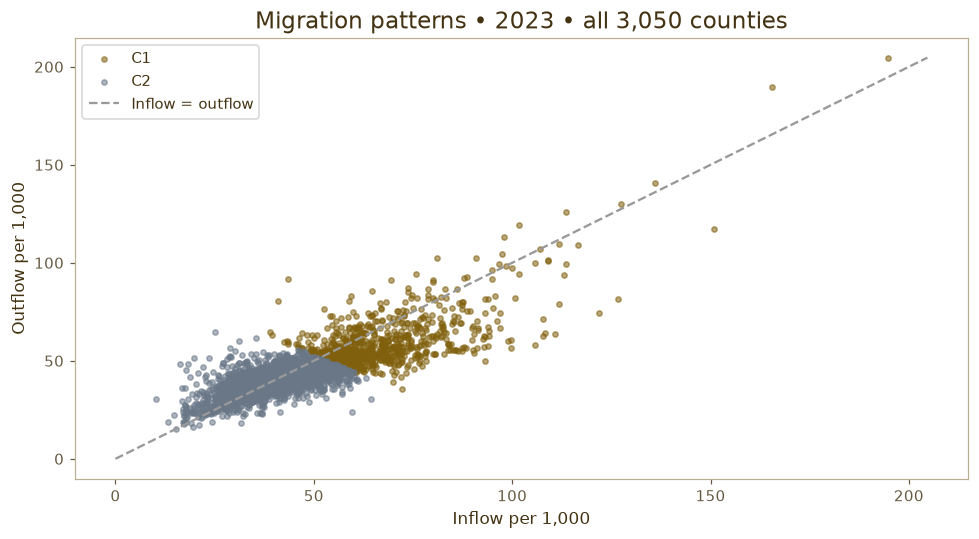

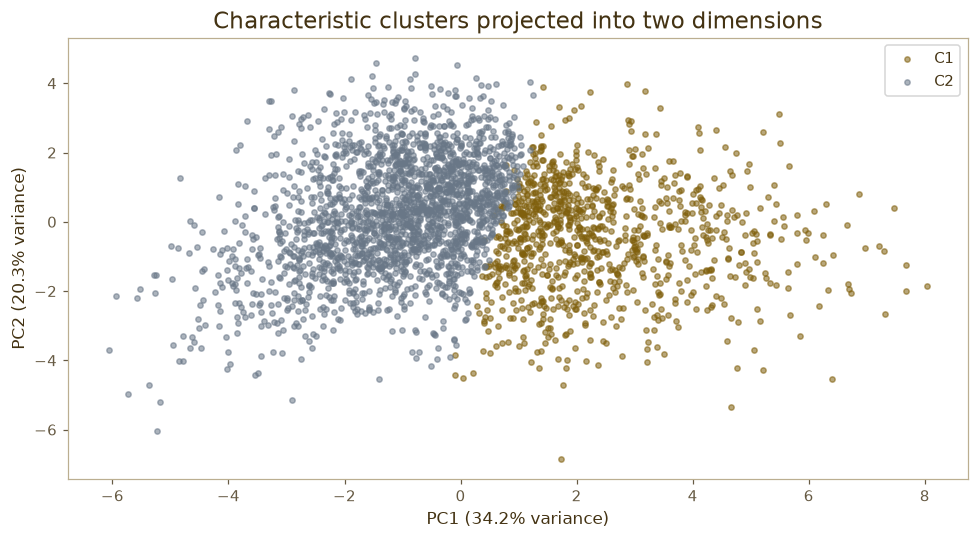

In [6]:
assignments = counties[['county_fips', 'county_name', 'year', 'population'] + COUNT_FIELDS + RATE_FIELDS].copy()
summary = provenance(INPUT, counties, FEATURES)
summary['k_values'] = K_VALUES
summary['selection_rule'] = 'Maximum full-cohort silhouette within k=2..8; ties favor smaller k'
summary['views'] = {}
for view in ['characteristics', 'migration']:
    matrix = views[view]
    k = selected[view, 'kmeans']; hk = selected[view, 'hierarchical']
    labels = fits[view, 'kmeans', k]; hlabels = fits[view, 'hierarchical', hk]
    assignments[view + '_kmeans'] = labels + 1
    assignments[view + '_hierarchical'] = hlabels + 1
    profile = counties.assign(cluster=labels + 1).groupby('cluster').agg(
        counties=('county_fips', 'size'), net_median=('net_individuals_per_1000', 'median'),
        net_q25=('net_individuals_per_1000', lambda s: s.quantile(.25)),
        net_q75=('net_individuals_per_1000', lambda s: s.quantile(.75)),
        inflow_median=('inflow_individuals_per_1000', 'median'),
        outflow_median=('outflow_individuals_per_1000', 'median'))
    for o in OUTCOME_DEFINITIONS:
        grouped = counties.assign(cluster=labels + 1).groupby('cluster')[o['rate']]
        for suffix, q in [('q25', .25), ('q75', .75)]:
            profile[o['id']+'_'+suffix] = grouped.quantile(q)
    zmeans = pd.DataFrame(matrix).assign(cluster=labels + 1).groupby('cluster').mean()
    descriptors = {}
    for cluster, zrow in zmeans.iterrows():
        names = LABELS if view == 'characteristics' else ['Inflow rate', 'Outflow rate']
        strongest = np.argsort(np.abs(zrow.to_numpy()))[-3:][::-1]
        descriptors[int(cluster)] = '; '.join(f'{names[j]} {zrow.iloc[j]:+.2f} SD' for j in strongest)
    profile['distinctive_features'] = [descriptors[i] for i in profile.index]
    profile.to_csv(DOWNLOAD/f'{view}-cluster-summary.csv')
    display(Markdown(f'### {view.title()} profiles'))
    rate_table = profile[[o['id']+'_'+s for o in OUTCOME_DEFINITIONS for s in ['median','q25','q75']]].copy()
    rate_table.columns = [o['label']+' '+s for o in OUTCOME_DEFINITIONS for s in ['median','Q1','Q3']]
    display(Markdown('Rates are IRS individuals per 1,000 ACS residents; Q1 and Q3 bound the middle half of counties.'))
    display(HTML(rate_table.to_html(float_format=lambda v: f'{v:.2f}')))
    stability = []
    with threadpool_limits(limits=1):
        for seed in [7, 19, 73, 101, 2026]:
            other = KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(matrix)
            stability.append(float(adjusted_rand_score(labels, other)))
    same_k = fits[view, 'hierarchical', k]
    bestrow = metrics.loc[(metrics.view == view) & (metrics.method == 'kmeans') & (metrics.k == k)].iloc[0]
    hrow = metrics.loc[(metrics.view == view) & (metrics.method == 'hierarchical') & (metrics.k == hk)].iloc[0]
    summary['views'][view] = dict(k=k, hierarchical_k=hk, silhouette=float(bestrow.silhouette),
        hierarchical_silhouette=float(hrow.silhouette),
        agreement=float(adjusted_rand_score(labels, hlabels)),
        same_k_agreement=float(adjusted_rand_score(labels, same_k)),
        seed_ari=stability, hierarchical_sizes=np.bincount(hlabels).tolist(),
        profiles=profile.reset_index().to_dict(orient='records'))
    agreement = summary['views'][view]['agreement']
    display(Markdown(f"K-means selects **k={k}** with Euclidean silhouette **{bestrow.silhouette:.3f}**. "
        f"Average-linkage hierarchical clustering selects **k={hk}** with cosine silhouette **{hrow.silhouette:.3f}**. "
        f"Each maximizes its own silhouette among k=2–8. The adjusted Rand index is **{agreement:.3f}**, "
        "indicating moderate agreement: the methods share some group structure while assigning many county pairs differently. "
        "ARI is adjusted for chance, with 0 representing chance-level agreement and 1 identical partitions. "
        "This description uses ARI as a continuum; silhouette scores should be compared within each distance metric."))
    cross = pd.crosstab(pd.Series(labels + 1, name='K-means'), pd.Series(hlabels + 1, name='Hierarchy'))
    cross.to_csv(DOWNLOAD/f'{view}-method-crosstab.csv')
    display(cross)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for o, ax in zip(OUTCOME_DEFINITIONS, axes):
        values = [counties.loc[labels == i, o['rate']] for i in range(k)]
        ax.boxplot(values, tick_labels=[f'C{i+1}' for i in range(k)], flierprops={'markersize': 2})
        ax.set(title=o['label'], xlabel='K-means cluster', ylabel='IRS individuals per 1,000 ACS residents')
    save_figure(fig, OUT, f'clustering-{view}-outcomes.png')
    fig, ax = plt.subplots(figsize=(10, 4.5))
    image = ax.imshow(zmeans, aspect='auto', cmap='BrBG', vmin=-2, vmax=2)
    ax.set(xticks=range(matrix.shape[1]), xticklabels=LABELS if view == 'characteristics' else ['Inflow rate', 'Outflow rate'],
           yticks=range(k), yticklabels=[f'C{i+1}' for i in range(k)], title=f'{view.title()}: mean standardized profiles')
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    fig.colorbar(image, ax=ax, label='Standard deviations from cohort mean (color saturates at ±2)')
    save_figure(fig, OUT, f'clustering-{view}-profiles.png')

labels = fits['migration', 'kmeans', selected['migration', 'kmeans']]
fig, ax = plt.subplots(figsize=(9, 5))
for i in np.unique(labels):
    sub = migration.loc[labels == i]
    ax.scatter(sub.iloc[:, 0], sub.iloc[:, 1], s=12, alpha=.55, color=COLORS[i], label=f'C{i+1}')
bound = float(migration.max().max()); ax.plot([0, bound], [0, bound], '--', color='#999999', label='Inflow = outflow')
ax.set(title=f'Migration patterns • {YEAR} • all {len(counties):,} counties', xlabel='Inflow per 1,000', ylabel='Outflow per 1,000')
ax.legend(); save_figure(fig, OUT, 'clustering-migration-scatter.png')
projection = PCA(n_components=2).fit(X)
scores = projection.transform(X)
labels = fits['characteristics', 'kmeans', selected['characteristics', 'kmeans']]
fig, ax = plt.subplots(figsize=(9, 5))
for i in np.unique(labels):
    ax.scatter(*scores[labels == i].T, s=12, alpha=.55, color=COLORS[i], label=f'C{i+1}')
ax.set(title='Characteristic clusters projected into two dimensions',
       xlabel=f'PC1 ({projection.explained_variance_ratio_[0]:.1%} variance)',
       ylabel=f'PC2 ({projection.explained_variance_ratio_[1]:.1%} variance)')
ax.legend(); save_figure(fig, OUT, 'clustering-characteristics-scatter.png')
summary['projection_variance'] = float(projection.explained_variance_ratio_.sum())

In [7]:
# Interpret group means and report concrete map examples, checked against assignments.
examples = {'characteristics': {1: ['06085','53033','51107'], 2: ['28011','54109','27031']},
            'migration': {1: ['45051','12119','37183'], 2: ['06037','17031','04013']}}
titles = {'characteristics': {1: 'Higher housing costs and educational attainment', 2: 'Lower housing costs and educational attainment'},
          'migration': {1: 'Higher turnover and larger typical net gains', 2: 'Lower turnover and near-balanced typical flows'}}
summary['interpretations'] = {}
for view in ['characteristics', 'migration']:
    summary['interpretations'][view] = []
    display(Markdown('### Interpreting ' + view + ' clusters'))
    for profile in summary['views'][view]['profiles']:
        cluster = profile['cluster']
        sample = assignments[assignments.county_fips.isin(examples[view][cluster])]
        assert len(sample) == 3 and (sample[view + '_kmeans'] == cluster).all()
        names = sample.county_name.tolist()
        text = (f"C{cluster}: {titles[view][cluster]}. The group contains {profile['counties']:,} counties. "
                f"Its strongest mean differences are {profile['distinctive_features']}. "
                f"Median inflow and outflow are {profile['inflow_median']:.2f} and {profile['outflow_median']:.2f} per 1,000; "
                f"median net migration is {profile['net_median']:.2f}, with the middle half between "
                f"{profile['net_q25']:.2f} and {profile['net_q75']:.2f}. "
                f"Inflow middle half: {profile['inflow_q25']:.2f}–{profile['inflow_q75']:.2f}; outflow middle half: {profile['outflow_q25']:.2f}–{profile['outflow_q75']:.2f}. "
                f"Examples on the map include {'; '.join(names)}.")
        summary['interpretations'][view].append({'cluster': cluster, 'title': titles[view][cluster], 'text': text, 'examples': names})
        display(Markdown(text))



### Interpreting characteristics clusters

C1: Higher housing costs and educational attainment. The group contains 964 counties. Its strongest mean differences are Log rent +1.09 SD; Log home value +1.04 SD; Bachelor’s+ % +1.02 SD. Median inflow and outflow are 51.31 and 48.05 per 1,000; median net migration is 2.00, with the middle half between -2.44 and 8.06. Inflow middle half: 40.82–64.13; outflow middle half: 40.96–57.22. Examples on the map include Santa Clara County, California; Loudoun County, Virginia; King County, Washington.

C2: Lower housing costs and educational attainment. The group contains 2,086 counties. Its strongest mean differences are Log rent -0.50 SD; Log home value -0.48 SD; Bachelor’s+ % -0.47 SD. Median inflow and outflow are 41.97 and 40.88 per 1,000; median net migration is 1.31, with the middle half between -3.09 and 6.59. Inflow middle half: 34.12–50.47; outflow middle half: 35.55–46.61. Examples on the map include Cook County, Minnesota; Bolivar County, Mississippi; Wyoming County, West Virginia.

### Interpreting migration clusters

C1: Higher turnover and larger typical net gains. The group contains 784 counties. Its strongest mean differences are Inflow rate +1.27 SD; Outflow rate +1.19 SD. Median inflow and outflow are 64.39 and 56.23 per 1,000; median net migration is 7.81, with the middle half between -0.18 and 14.50. Inflow middle half: 57.98–73.74; outflow middle half: 52.09–64.17. Examples on the map include Sumter County, Florida; Wake County, North Carolina; Horry County, South Carolina.

C2: Lower turnover and near-balanced typical flows. The group contains 2,266 counties. Its strongest mean differences are Inflow rate -0.44 SD; Outflow rate -0.41 SD. Median inflow and outflow are 40.12 and 39.91 per 1,000; median net migration is 0.62, with the middle half between -3.49 and 4.49. Inflow middle half: 33.35–46.54; outflow middle half: 34.88–44.14. Examples on the map include Maricopa County, Arizona; Los Angeles County, California; Cook County, Illinois.

The cluster interpretations should be understood as descriptive county averages. Counties within each group have varied migration outcomes. Regional examples identify individual members, while neighboring counties can belong to another group.

### Comparing the two views

A contingency table connects independently discovered migration and characteristic groups. Row-normalized percentages answer which migration patterns occur within each characteristic profile. When determining how migration flows vary across the country, the rankings below complement the existing EDA migration map:

migration_kmeans,1,2
characteristics_kmeans,,
1,438,526
2,346,1740


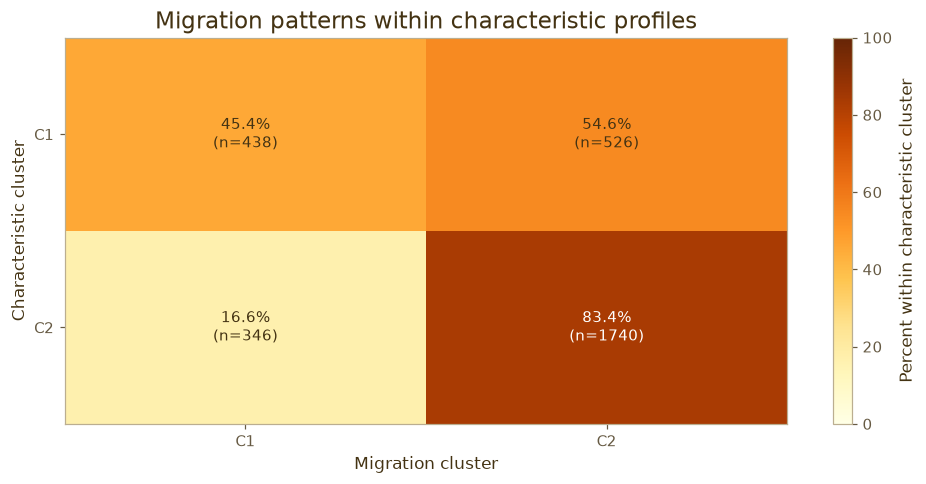

,county_name,inflow_individuals,inflow_individuals_per_1000
175,"Los Angeles County, California",174784.0,17.747441
2539,"Harris County, Texas",163262.0,34.308982
74,"Maricopa County, Arizona",149222.0,33.219597
2496,"Dallas County, Texas",119745.0,45.988273
567,"Cook County, Illinois",119132.0,22.972680


,county_name,outflow_individuals,outflow_individuals_per_1000
175,"Los Angeles County, California",259326.0,26.331774
2539,"Harris County, Texas",183281.0,38.515910
567,"Cook County, Illinois",159992.0,30.851870
2496,"Dallas County, Texas",148643.0,57.086599
74,"Maricopa County, Arizona",144612.0,32.193326


In [8]:
cross = pd.crosstab(assignments.characteristics_kmeans, assignments.migration_kmeans)
cross.to_csv(DOWNLOAD/'migration-characteristics-crosstab.csv')
display(cross)
fig, ax = plt.subplots(figsize=(9, 4.5))
row_pct = cross.div(cross.sum(axis=1), axis=0) * 100
im = ax.imshow(row_pct, cmap='YlOrBr', vmin=0, vmax=100, aspect='auto')
for i in range(len(cross)):
    for j in range(len(cross.columns)):
        ax.text(j, i, f'{row_pct.iloc[i,j]:.1f}%\n(n={cross.iloc[i,j]})', ha='center', va='center',
                color='white' if row_pct.iloc[i,j] > 60 else '#443313')
ax.set(xticks=range(len(cross.columns)), xticklabels=[f'C{i}' for i in cross.columns],
       yticks=range(len(cross)), yticklabels=[f'C{i}' for i in cross.index],
       xlabel='Migration cluster', ylabel='Characteristic cluster', title='Migration patterns within characteristic profiles')
fig.colorbar(im, ax=ax, label='Percent within characteristic cluster')
save_figure(fig, OUT, 'clustering-cross-view.png')
rankings = {}
for measure in ['inflow_individuals', 'outflow_individuals']:
    top = counties.nlargest(5, measure)[['county_name', measure, measure + '_per_1000']]
    display(top)
    rankings[measure] = top.to_dict(orient='records')
summary['rankings'] = rankings
assignments.to_csv(DOWNLOAD/'cluster-assignments.csv', index=False)

## Conclusions and exported findings

In [9]:
# One row per selected method and cluster; all outcomes use rates per 1,000 ACS residents.
summary_rows = []
for view in ['characteristics', 'migration']:
    result = summary['views'][view]
    for method, label in [('kmeans', 'K-means'), ('hierarchical', 'Hierarchical')]:
        k = selected[view, method]
        labels = fits[view, method, k] + 1
        matrix = views[view]
        names = LABELS if view == 'characteristics' else ['Inflow rate', 'Outflow rate']
        for cluster in range(1, k+1):
            subset = counties.loc[labels == cluster]
            means = matrix[labels == cluster].mean(axis=0)
            strongest = np.argsort(np.abs(means))[-3:][::-1]
            reading = '; '.join(f'{names[j]} {means[j]:+.2f} SD relative to the cohort mean' for j in strongest)
            if method == 'kmeans':
                reading = next(r['title'] for r in summary['interpretations'][view] if r['cluster'] == cluster) + '. ' + reading
            row = {'View': view.title(), 'Method': label, 'Selected k': k,
                   'Silhouette': result['silhouette' if method == 'kmeans' else 'hierarchical_silhouette'],
                   'Cluster': f'C{cluster}', 'Counties': len(subset), 'Interpretation': reading}
            for o in OUTCOME_DEFINITIONS:
                for name, q in [('Median', .5), ('Q1', .25), ('Q3', .75)]:
                    row[o['label']+' '+name] = float(subset[o['rate']].quantile(q))
            summary_rows.append(row)
conclusion_table = pd.DataFrame(summary_rows)
conclusion_table.to_csv(DOWNLOAD/'clustering-conclusion-summary.csv', index=False)
summary['conclusion_table'] = summary_rows
summary['outcomes'] = OUTCOME_DEFINITIONS
summary['metrics'] = json.loads(metrics.to_json(orient='records'))
c1, c2 = summary['views']['characteristics']['profiles']
m1, m2 = summary['views']['migration']['profiles']
summary['conclusions'] = [
    f"Both methods select two characteristic profiles and two migration groups among {len(counties):,} counties. Agreement between methods is moderate (adjusted Rand index {summary['views']['characteristics']['agreement']:.3f} for characteristics and {summary['views']['migration']['agreement']:.3f} for migration), so the group boundaries depend on the chosen geometry.",
    f"The higher-income, education and housing-cost characteristic profile has higher median inflow and outflow rates ({c1['inflow_median']:.2f} and {c1['outflow_median']:.2f}) than the other profile ({c2['inflow_median']:.2f} and {c2['outflow_median']:.2f}). Median net migration differs by only {abs(c1['net_median']-c2['net_median']):.2f} per 1,000, and the middle halves of the net-migration distributions overlap substantially. The characteristic profiles primarily distinguish two-way turnover.",
    f"Clustering inflow and outflow directly separates higher-turnover and lower-turnover counties. Their median net rates are {m1['net_median']:.2f} and {m2['net_median']:.2f} per 1,000, respectively. These outcome contrasts follow the rate-based grouping; the characteristic analysis compares migration after fitting. All reported rates describe IRS-covered individuals per 1,000 ACS residents."
]
for sentence in summary['conclusions']: display(Markdown(sentence))
write_json(ROOT/'website/data/clustering.json', summary)


Both methods select two characteristic profiles and two migration groups among 3,050 counties. Agreement between methods is moderate (adjusted Rand index 0.548 for characteristics and 0.448 for migration), so the group boundaries depend on the chosen geometry.

The higher-income, education and housing-cost characteristic profile has higher median inflow and outflow rates (51.31 and 48.05) than the other profile (41.97 and 40.88). Median net migration differs by only 0.70 per 1,000, and the middle halves of the net-migration distributions overlap substantially. The characteristic profiles primarily distinguish two-way turnover.

Clustering inflow and outflow directly separates higher-turnover and lower-turnover counties. Their median net rates are 7.81 and 0.62 per 1,000, respectively. These outcome contrasts follow the rate-based grouping; the characteristic analysis compares migration after fitting. All reported rates describe IRS-covered individuals per 1,000 ACS residents.

In [10]:
# Browser figures use the same fitted arrays and hierarchy as the notebook.
chart_data = {'profiles': {}, 'trees': {}}
for view, matrix in views.items():
    labels = assignments[view + '_kmeans'].to_numpy()
    chart_data['profiles'][view] = {'labels': LABELS if view == 'characteristics' else ['Inflow rate', 'Outflow rate'],
        'values': pd.DataFrame(matrix).groupby(labels).mean().to_numpy().tolist()}
    tree = dendrogram(trees[view], truncate_mode='lastp', p=30, no_plot=True)
    chart_data['trees'][view] = {key: tree[key] for key in ['icoord', 'dcoord', 'ivl']}
chart_data['counties'] = assignments.assign(inflow=migration.iloc[:,0], outflow=migration.iloc[:,1],
    PC1=scores[:,0], PC2=scores[:,1]).to_dict(orient='records')
chart_data['toy'] = {'points': toy.tolist(), 'labels': toy_fit.labels_.tolist(), 'centers': toy_fit.cluster_centers_.tolist()}
tree = dendrogram(linkage(toy_z, method='average', metric='cosine'), labels=list('ABCDEF'), no_plot=True)
chart_data['trees']['toy'] = {key: tree[key] for key in ['icoord', 'dcoord', 'ivl']}
write_json(DOWNLOAD/'clustering-charts.json', chart_data)

